# Session 11 Statistical Analysis

**Learning goals:**

- understand the purpose and logic of statistical testing
- follow a statistical testing workflow from question to report
- create null and alternative hypotheses
- perform a t-test in Python
- interpret p-values correctly

**Prerequisites:**

- basic Python: variables, lists, function calls, and loops
- pandas: selecting rows and columns, checking missing values, and calculating grouped summaries
- descriptive statistics: sample size, mean, and standard deviation
- basic data visualisation: reading histograms and box plots
- Jupyter notebooks: running code cells and writing Markdown explanations


## Outline

1. Introduction to Significance Testing
2. How to Compare Two Groups: A Sampling Approach
3. Significance Testing Workflow
4. Independent t-Test
5. Case Study: Do Tips Differ by Sex?
6. Interpreting p-value
7. The Multiple Comparisons Problem
8. Exercise: Do Total Bills Differ by Time?


## 1. Introduction to Significance Testing

The American Statistical Association defines statistics as "the science of learning from data and of measuring, controlling, and communicating uncertainty." [Source: ASA Newsroom](https://www.amstat.org/asa-newsroom)

**Statistical analysis** involves:

- **Group evidence**: Use data from many samples, not just one.

- **Group comparison**: Compare the data between groups, group to group comparison.

- **Variation and bias**: Reduce the influence from unusual values, and sample error before making conclusions.

A common way to compare two groups is to compare their means or rates. The two examples below show why that approach alone can be misleading, and why we need the tools of statistical analysis to draw reliable conclusions.


### 1.1 Example 1: Student scores: is the difference real?

Two classes each have 15 students. Scores range from 0 to 100.

| Student | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | Average |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **Class A** | 74.4 | 63.7 | 78.0 | 79.5 | 56.4 | 61.6 | 73.0 | 69.5 | 71.9 | 65.2 | 79.0 | 78.2 | 72.5 | 81.0 | 75.7 | **72.0** |
| **Class B** | 69.1 | 79.0 | 68.3 | 83.0 | 75.6 | 74.5 | 70.6 | 85.8 | 74.8 | 72.6 | 73.2 | 80.3 | 78.9 | 79.3 | 79.4 | **76.3** |

**Question:** Class B's mean (76.3) is higher than Class A's (72.0). Does that mean Class B truly performed better, or could the difference be due to the particular students sampled?


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Student scores for each class.
class_A = np.array([74.4, 63.7, 78.0, 79.5, 56.4, 61.6, 73.0, 69.5, 71.9, 65.2, 79.0, 78.2, 72.5, 81.0, 75.7])
class_B = np.array([69.1, 79.0, 68.3, 83.0, 75.6, 74.5, 70.6, 85.8, 74.8, 72.6, 73.2, 80.3, 78.9, 79.3, 79.4])

scores = pd.DataFrame({'Class A': class_A, 'Class B': class_B})

summary = scores.agg(['count', 'mean', 'median', 'std', 'min', 'max'])
display(summary.round(2))

,Class A,Class B
count,15.00,15.00
mean,71.97,76.29
median,73.00,75.60
std,7.34,5.08
min,56.40,68.30
max,81.00,85.80


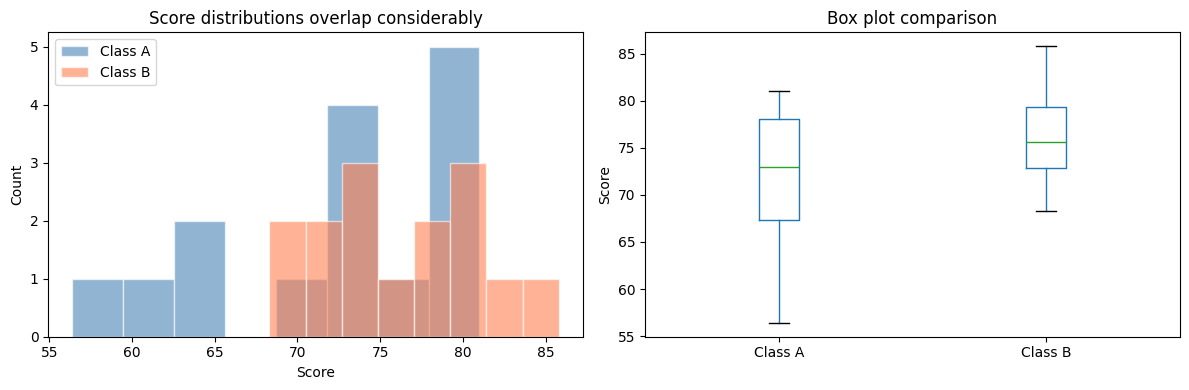

Observed mean difference (B − A): 4.32 points


In [2]:
# Visualise the two distributions side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
for col, colour in zip(['Class A', 'Class B'], ['steelblue', 'coral']):
    axes[0].hist(scores[col], bins=8, alpha=0.6, label=col, color=colour, edgecolor='white')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Score distributions overlap considerably')
axes[0].legend()

# Box plot
scores.boxplot(ax=axes[1], grid=False)
axes[1].set_ylabel('Score')
axes[1].set_title('Box plot comparison')

fig.tight_layout()
plt.show()

print(f'Observed mean difference (B − A): {class_B.mean() - class_A.mean():.2f} points')

The means differ by a few points, yet the distributions overlap heavily. If we had drawn a different sample of 15 students from each population, the gap could easily reverse. **A mean difference alone cannot tell us whether the underlying populations truly differ.**


### 1.2 Example 2: A/B testing: is the new design better?

An e-commerce company tests two page designs. Each version is shown to 1,000 visitors.

| Design | Visitors | Purchases | Conversion rate |
| --- | ---: | ---: | ---: |
| A (old) | 1,000 | 52 | 5.2% |
| B (new) | 1,000 | 58 | 5.8% |

Design B's conversion rate is 0.6 percentage points higher. Should the company roll out Design B?


In [3]:
# Simulate the A/B test scenario.
n_A, n_B = 1000, 1000
purchases_A, purchases_B = 52, 58
rate_A, rate_B = purchases_A / n_A, purchases_B / n_B

print(f'Conversion rate A: {rate_A:.1%}')
print(f'Conversion rate B: {rate_B:.1%}')
print(f'Observed difference (B − A): {rate_B - rate_A:.1%}')
print()
print('Is 0.6 percentage points a real improvement, or random fluctuation?')

Conversion rate A: 5.2%
Conversion rate B: 5.8%
Observed difference (B − A): 0.6%

Is 0.6 percentage points a real improvement, or random fluctuation?


If the company decides based on the 0.6% gap alone, it may invest heavily in rolling out a design that offers no real benefit. **We need a systematic method to decide whether an observed difference is large enough to be unlikely from random variation alone.**

### 1.3 Why we need significance testing

Both examples share the same core question: *is the observed difference real, or could it have arisen by chance?*

**Significance testing** provides a structured answer. It asks: if there were **no true difference** between the two groups, how likely would we be to observe a difference at least as large as the one we found?

Key concepts we will explore in the following sections:

- **Null hypothesis**: the default assumption that there is no difference
- **p-value**: how likely the observed result is under the null hypothesis
- **Significance level (α)**: a pre-set threshold for decision-making


## 2. How to Compare Two Groups: A Sampling Approach

How can we tell whether the difference between two groups is real or just due to chance? The process follows five steps:

1. **Assume no difference**: Assume the two groups come from the same population, so any observed difference is due to chance.
2. **Combine the two groups**: Pool all observations into one dataset.
3. **Sample from the combined data**: Randomly split the pooled data into two groups, many times.
4. **Calculate the difference for each split**: Record the mean difference from each random split to build a distribution of differences by chance.
5. **Locate the observed difference**: Calculate where our actual observed difference falls in that distribution. How likely is it to see such a difference by chance alone?

We use the student-score data from Example 1 to walk through each step.


### 2.1 Start with an assumption: no difference

The reasoning begins with an assumption: **suppose the two classes are not really different**. All 30 students come from the same population, and we just happened to split them into two groups.

If that is true, then the labels "Class A" and "Class B" are meaningless. We could combine all 30 scores into one big pool, randomly split them into two groups of 15, and any difference in means would be purely due to chance.

By repeating this random splitting many times, we can build a **distribution of differences that arise from chance alone**. Then we check: where does our observed difference fall in that distribution?


In [4]:
# Step 1: Combine both classes into one pool (assume no difference).
all_scores = np.concatenate([class_A, class_B])
observed_diff = class_B.mean() - class_A.mean()

# Step 2: Randomly split into two groups 10,000 times and record the mean difference each time.
n_permutations = 10_000
permuted_diffs = np.empty(n_permutations)

rng_perm = np.random.default_rng(0)
for i in range(n_permutations):
    shuffled = rng_perm.permutation(all_scores)          # Shuffle all 30 scores.
    group_1 = shuffled[:15]                               # Random group 1.
    group_2 = shuffled[15:]                               # Random group 2.
    permuted_diffs[i] = group_2.mean() - group_1.mean()  # Difference by chance.

print(f'Observed mean difference (B − A): {observed_diff:.2f}')
print(f'Simulated differences, mean: {permuted_diffs.mean():.3f}, std: {permuted_diffs.std():.3f}')

Observed mean difference (B − A): 4.32
Simulated differences, mean: 0.046, std: 2.389


### 2.2 Where does our observed difference fall?

The histogram below shows the distribution of mean differences from 10,000 random splits. This is what differences look like **when there is no real difference** between the two groups.

The red dashed line marks our observed difference. If it falls well within the bulk of the distribution, the observed difference is easily explained by chance. If it falls far in the tail, the difference is unlikely to have arisen by chance alone.


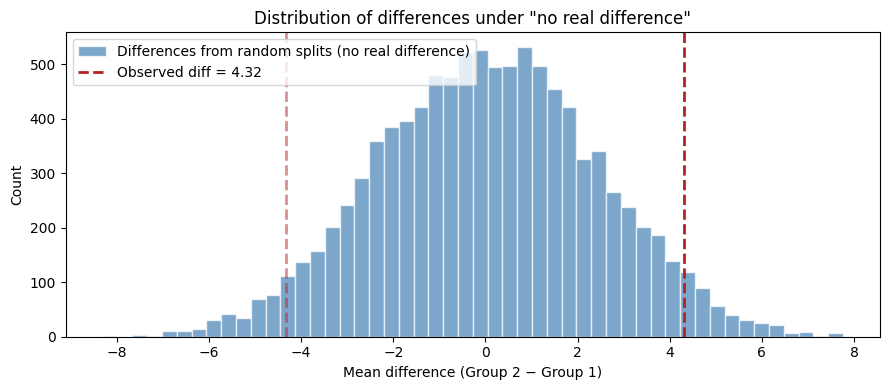

Proportion of random splits with |difference| ≥ 4.32: 0.0693
→ More than 5% of random splits produce a difference this large.
  The observed difference could plausibly be due to chance.


In [5]:
# Step 3: See where the observed difference falls in the distribution.
proportion_as_extreme = np.mean(np.abs(permuted_diffs) >= abs(observed_diff))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(permuted_diffs, bins=50, color='steelblue', edgecolor='white', alpha=0.7,
        label='Differences from random splits (no real difference)')
ax.axvline(observed_diff, color='firebrick', linestyle='--', linewidth=2,
           label=f'Observed diff = {observed_diff:.2f}')
ax.axvline(-observed_diff, color='firebrick', linestyle='--', linewidth=2, alpha=0.5)
ax.set_xlabel('Mean difference (Group 2 − Group 1)')
ax.set_ylabel('Count')
ax.set_title(f'Distribution of differences under "no real difference"')
ax.legend()
fig.tight_layout()
plt.show()

print(f'Proportion of random splits with |difference| ≥ {abs(observed_diff):.2f}: {proportion_as_extreme:.4f}')
if proportion_as_extreme < 0.05:
    print('→ Less than 5% of random splits produce a difference this large.')
    print('  The observed difference is unlikely to be due to chance alone.')
else:
    print('→ More than 5% of random splits produce a difference this large.')
    print('  The observed difference could plausibly be due to chance.')

**Intuition:** We asked *"if there were no real difference, how often would random splitting produce a gap at least this large?"* The proportion of random splits that match or exceed our observed difference tells us how unusual our result is. This proportion is what statisticians call the **p-value**.


### 2.3 From random sampling to t-test

The sampling approach above gives clear intuition, but it requires thousands of random splits. Is there a shortcut?

It turns out that when we standardise the mean difference by its **standard error**, the distribution of these standardised differences follows a well-known mathematical shape called the **t distribution**. This means:

1. We do **not** need to run thousands of random splits.
2. We can calculate a single number, the **t statistic**, directly from the two samples.
3. We can look up where this t statistic falls in the t distribution to get the **p-value**.

$$t = \frac{\text{observed mean difference}}{\text{standard error of the difference}}$$

The **p-value** is the area in the tails of the t distribution beyond the observed t. A small p-value means the observed difference is far in the tail: unlikely to have arisen by chance.

| Concept | Sampling approach | t-test |
| --- | --- | --- |
| Assumption | Combine data, randomly split | Assume equal population means |
| Distribution of differences | Built by repeated random sampling | Known mathematically (t distribution) |
| How to get p-value | Count proportion of splits ≥ observed | Calculate area in tails of t distribution |
| Advantage | Intuitive, no assumptions about shape | Fast, no resampling needed, widely used |

The t-test is essentially a mathematical shortcut for what we just did by hand. The following sections formalise the workflow and introduce Python tools to perform t-tests.


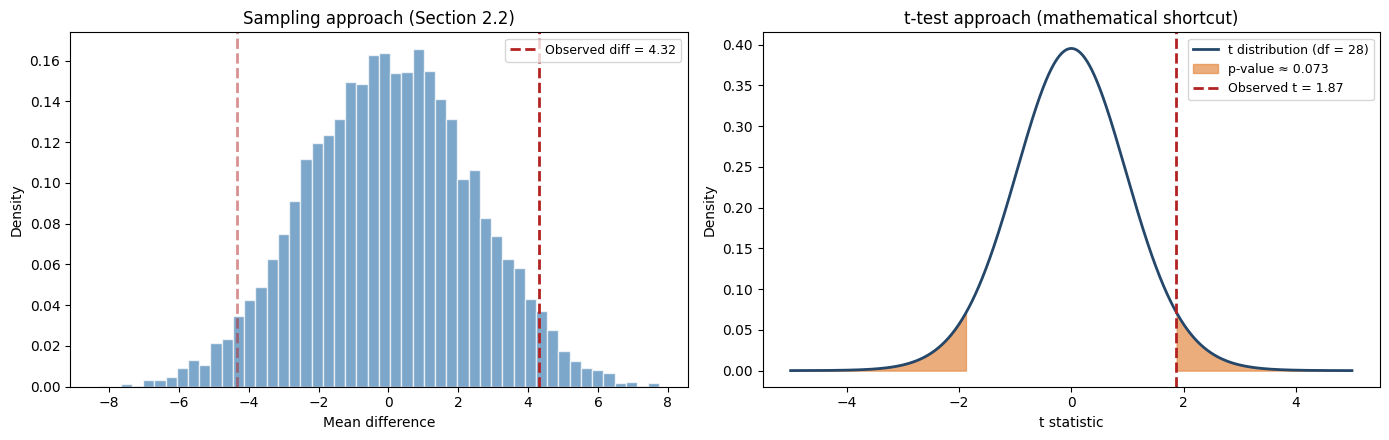

Sampling approach, proportion as extreme: 0.0693
t-test approach : t = 1.8742, p-value = 0.0727

Both approaches answer the same question and give similar results.
The t-test achieves it with a formula instead of 10,000 random splits.


In [6]:
from scipy import stats

# Calculate the t statistic and p-value directly from the two samples.
t_stat_demo, p_value_demo = stats.ttest_ind(class_B, class_A, equal_var=False)

# Build the t distribution curve for comparison with the sampling approach.
df_demo = len(class_A) + len(class_B) - 2  # Approximate degrees of freedom.
x = np.linspace(-5, 5, 1000)
t_density = stats.t.pdf(x, df=df_demo)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left panel: the sampling distribution from Section 2.2 (for reference).
axes[0].hist(permuted_diffs, bins=50, color='steelblue', edgecolor='white', alpha=0.7, density=True)
axes[0].axvline(observed_diff, color='firebrick', linestyle='--', linewidth=2,
                label=f'Observed diff = {observed_diff:.2f}')
axes[0].axvline(-observed_diff, color='firebrick', linestyle='--', linewidth=2, alpha=0.5)
axes[0].set_xlabel('Mean difference')
axes[0].set_ylabel('Density')
axes[0].set_title('Sampling approach (Section 2.2)')
axes[0].legend(fontsize=9)

# Right panel: the t distribution with the observed t statistic and shaded p-value.
axes[1].plot(x, t_density, color='#24476a', linewidth=2, label=f't distribution (df = {df_demo})')
axes[1].fill_between(x, 0, t_density, where=(x <= -abs(t_stat_demo)), color='#e48b45', alpha=0.7)
axes[1].fill_between(x, 0, t_density, where=(x >= abs(t_stat_demo)), color='#e48b45', alpha=0.7,
                     label=f'p-value ≈ {p_value_demo:.3f}')
axes[1].axvline(t_stat_demo, color='firebrick', linestyle='--', linewidth=2,
                label=f'Observed t = {t_stat_demo:.2f}')
axes[1].set_xlabel('t statistic')
axes[1].set_ylabel('Density')
axes[1].set_title('t-test approach (mathematical shortcut)')
axes[1].legend(fontsize=9)

fig.tight_layout()
plt.show()

print(f'Sampling approach, proportion as extreme: {proportion_as_extreme:.4f}')
print(f't-test approach : t = {t_stat_demo:.4f}, p-value = {p_value_demo:.4f}')
print()
print('Both approaches answer the same question and give similar results.')
print('The t-test achieves it with a formula instead of 10,000 random splits.')

## 3. Significance Testing Workflow

A structured workflow helps analysts proceed consistently and avoid common mistakes such as setting the significance level after seeing the result.

### 3.1 The seven-step workflow

| Step | Description | Key action |
| --- | --- | --- |
| 1. Define the question | What comparison do you want to make? | State clearly |
| 2. Identify variables | What is the outcome? What are the groups? | Numeric vs. categorical |
| 3. Inspect data | Distributions, sample sizes, outliers, missing values | EDA and visualisation |
| 4. Set hypotheses and threshold | H₀, H₁, and α = 0.05 | Write them down **before** testing |
| 5. Choose a method | t-test, ANOVA, chi-square, etc. | Based on variable types and assumptions |
| 6. Calculate and interpret | Run the test, obtain t, df, p-value | Compare p to α |
| 7. Write a report | Organise the question, variables, data inspection, hypotheses, method, results, and conclusion into a notebook report | Combine Markdown explanations, code, and outputs |


### 3.2 Creating null and alternative hypotheses

Setting hypotheses **before** examining results is essential. It prevents the analyst from adjusting expectations to match the data.

**Null hypothesis (H₀):** There is **no** difference between the two groups. Any observed difference is due to random variation.

**Alternative hypothesis (H₁):** There **is** a difference between the two groups. The observed difference is unlikely to have arisen from random variation alone.

**Significance level (α = 0.05):** Before testing, we set a threshold. If the p-value falls below α, we reject H₀. This means: *if H₀ were true, we accept a 5% chance of wrongly rejecting it*. This threshold is chosen **before** the test, not adjusted afterwards.


**Practice: write hypotheses for the examples in Section 1.**

*Example 1: Student scores:*

- H₀: The population mean score of Class A equals the population mean score of Class B.
- H₁: The population mean scores differ.
- α = 0.05.

*Example 2: A/B test:*

- H₀: The population conversion rate of Design A equals the population conversion rate of Design B.
- H₁: The population conversion rates differ.
- α = 0.05.


## 4. t-Test

This course focuses on the **independent-samples t-test** for comparing the means of two independent groups.


### 4.1 What the t-test compares

Use an independent t-test when the outcome is **continuous** and the grouping variable has **two categories**, such as scores from different students in Class A and Class B.

- **H₀:** The two population means are equal: μ_A = μ_B.
- **H₁:** The population means differ: μ_A ≠ μ_B.

The t statistic expresses the observed mean difference relative to its standard error. Compare the p-value with **α = 0.05**, and report the mean difference to describe its size and direction.

- Observations within and between groups should be independent.
- For small samples, each group's data should be approximately normally distributed, with no extreme outliers.
- We use **Welch's t-test**, which allows unequal population variances, as the main method in this course.


### 4.2 t-test in Python: Three Approaches

This section introduces three approaches to testing a difference in means: a direct t-test with `scipy`, a regression model with `statsmodels`, and a t-test with an extended results table using `pingouin`.

| Package | Function | Key feature |
| --- | --- | --- |
| `scipy.stats` | `ttest_ind()` | Lightweight; returns t statistic and p-value |
| `statsmodels` | `smf.ols()` + `.fit()` | Formula interface; detailed coefficient table |
| `pingouin` | `pg.ttest()` | Compact table; includes effect size (Cohen's d) |


#### Quick demonstration with the student-score data

We use the Class A and Class B data from Section 1 to show all three approaches on the same problem.


#### Approach 1: A direct t-test with SciPy

**Function and parameters:** `stats.ttest_ind(class_B, class_A, equal_var=False)`.

- `class_B` and `class_A` are the two independent score samples. Their order makes the mean difference **Class B minus Class A**.
- `equal_var=False` selects Welch's t-test, allowing the population variances to differ.
- The function returns a result containing the t statistic and p-value. The assignment stores these in `t_stat_sp` and `p_value_sp`.

[Function reference: SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)


In [7]:
# Approach: scipy
from scipy import stats

t_stat_sp, p_value_sp = stats.ttest_ind(class_B, class_A, equal_var=False)  # Welch's t-test.
print('--- scipy.stats ---')
print(f't statistic: {t_stat_sp:.4f}')
print(f'p-value:     {p_value_sp:.4f}')

--- scipy.stats ---
t statistic: 1.8742
p-value:     0.0727


**Reading the SciPy output:**

- **t statistic ≈ 1.8742:** Class B's sample mean is about 1.87 standard errors above Class A's. The positive sign follows the input order.
- **p-value ≈ 0.0727:** Under H₀, a result at least as extreme occurs with probability about 7.27%.

Since p > 0.05, we fail to reject H₀. There is insufficient evidence that the population mean scores differ; this does not establish that they are equal.


#### Approach 2: A regression model with statsmodels

**Function and parameters:** `smf.ols('score ~ C(class_label)', data=scores_long).fit()`.

- `scores_long` has one row per student: `score` contains scores and `class_label` identifies A or B.
- In the formula, `score` is the outcome; `~` separates it from the predictor.
- `C(class_label)` treats the labels as categories. Class A is the reference here.
- `data=scores_long` supplies the DataFrame. `.fit()` estimates the model; an intercept is included by default.

The displayed table is assembled from `model.params`, `model.tvalues`, `model.pvalues`, and `model.conf_int()`. Its columns contain estimates, t statistics, p-values, and the lower/upper bounds of default 95% confidence intervals.

[Formula reference](https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html) · [Results reference](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.html)


In [8]:
# Approach: statsmodels
import statsmodels.formula.api as smf

# Reshape data into a tidy DataFrame for the formula interface.
scores_long = pd.DataFrame({
    'score': np.concatenate([class_A, class_B]),
    'class_label': ['A'] * len(class_A) + ['B'] * len(class_B),
})

model = smf.ols('score ~ C(class_label)', data=scores_long).fit()

coef_table = pd.DataFrame({
    'coefficient': model.params,
    't_statistic': model.tvalues,
    'p_value': model.pvalues,
    'conf_low': model.conf_int()[0],
    'conf_high': model.conf_int()[1],
})

print('--- statsmodels ---')
display(coef_table.round(4))

--- statsmodels ---


,coefficient,t_statistic,p_value,conf_low,conf_high
Intercept,71.9733,44.1594,0.0000,68.6347,75.3119
C(class_label)[T.B],4.3200,1.8742,0.0714,-0.4015,9.0415


**Reading the statsmodels output:**

- **Intercept ≈ 71.9733:** Class A's estimated mean. Its p-value tests whether that mean equals zero.
- **`C(class_label)[T.B]` ≈ 4.3200:** Class B's estimated mean minus Class A's. Read this row for the group comparison.
- Its **t ≈ 1.8742**, **p ≈ 0.0714**, and **95% interval ≈ [−0.40, 9.04]** provide insufficient evidence of a population mean difference at α = 0.05.

Default OLS inference here uses a common residual variance, equivalent to the pooled-variance t-test, rather than Welch's test. This explains the slightly different p-value.


#### Approach 3: A results table with Pingouin

**Function and parameters:** `pg.ttest(class_B, class_A, paired=False, correction=True)`.

- `class_B` and `class_A` supply the score samples; the difference is **B minus A**.
- `paired=False` specifies independent groups.
- `correction=True` selects Welch's correction for unequal variances. It is unrelated to multiple-comparison correction.
- The function returns a DataFrame stored in `pg_result`; `display(pg_result)` shows it.

[Function reference: Pingouin source documentation](https://github.com/raphaelvallat/pingouin/blob/main/src/pingouin/parametric.py)


In [9]:
# Approach: pingouin
import pingouin as pg

pg_result = pg.ttest(class_B, class_A, paired=False, correction=True)  # Welch correction.

print('--- pingouin ---')
display(pg_result)

--- pingouin ---


,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,1.874217,24.911005,two-sided,0.072675,"[-0.43, 9.07]",0.684367,0.440426,1.253


**Reading the Pingouin output:**

| Column | Meaning |
| --- | --- |
| `T` | t statistic |
| `dof` | Degrees of freedom used for inference; Welch's value can be fractional |
| `alternative` | The alternative hypothesis used by the function |
| `p_val` | p-value for the mean comparison |
| `CI95` | 95% confidence interval for the population mean difference, B minus A |
| `cohen_d` | Absolute standardised mean difference (effect size) |
| `power` | Achieved power computed from the observed effect and sample sizes |
| `BF10` | Bayes factor for H₁ relative to H₀ under the package's prior |

Here **T ≈ 1.8742**, **p ≈ 0.0727**, and **CI95 ≈ [−0.43, 9.07]** indicate insufficient evidence of a population mean difference at α = 0.05. **Cohen's d ≈ 0.684** describes the observed effect magnitude. Start with `T`, `p_val`, and `CI95`; the additional measures are optional. Achieved power does not independently establish evidence for H₀.


## 5. Case Study: Do Tips Differ by Sex?

This case study is a notebook report using the `tips` dataset. Each step contributes part of the report: the question, variables, data inspection, hypotheses, method, and results with a conclusion. The main analysis uses SciPy; two optional alternatives are shown afterwards.

### Load the tips dataset

Load the dataset with Seaborn and preview the first five rows.


In [10]:
import seaborn as sns

# Load the tips dataset.
tips = sns.load_dataset('tips')

print('Rows and columns:', tips.shape)
tips.head()

Rows and columns: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Each row records one restaurant bill and its associated tip. The dataset contains the following variables:

| Variable | Meaning | Type |
| --- | --- | --- |
| `total_bill` | total restaurant bill in US dollars | numeric |
| `tip` | tip amount in US dollars | numeric |
| `sex` | category recorded in the source dataset | categorical |
| `smoker` | whether the party was in the smoking area | categorical |
| `day` | abbreviated day of the week | categorical |
| `time` | lunch or dinner | categorical |
| `size` | number of people in the dining party | numeric count |

The category labels describe how the data was recorded; they should not be interpreted as complete demographic definitions.


### Step 1: Define the question

**Do Male and Female customers leave different mean tips?**


### Step 2: Identify variables

- **Outcome (dependent variable):** `tip`: numeric, continuous.
- **Grouping (independent variable):** `sex`: categorical, two levels: Female, Male.


### Step 3: Inspect data


In [11]:
# Check for missing values in the test variables.
print('Missing values in test variables:')
display(tips[['sex', 'tip']].isna().sum().to_frame('missing'))

# Group summaries.
print('Group summaries:')
display(tips.groupby('sex')['tip'].agg(['count', 'mean', 'median', 'std']).round(3))

Missing values in test variables:


,missing
sex,0
tip,0


Group summaries:


,count,mean,median,std
sex,,,,
Male,157,3.090,3.00,1.489
Female,87,2.833,2.75,1.159


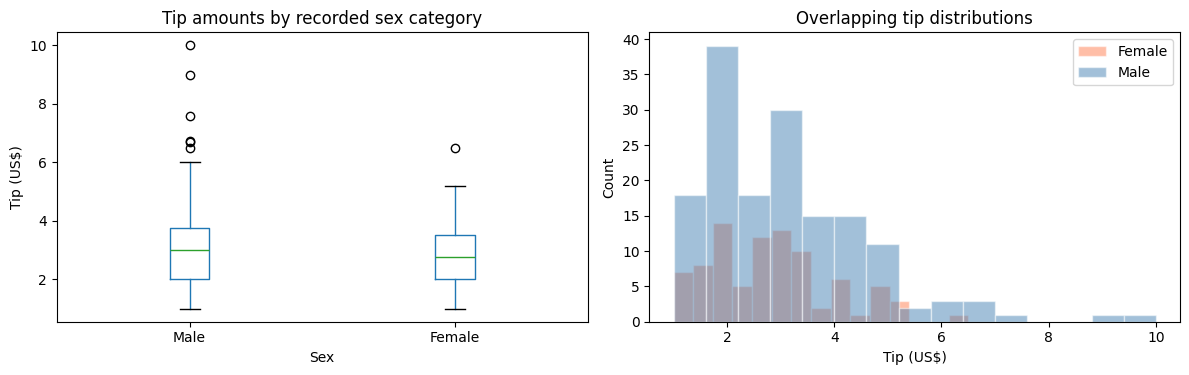

In [12]:
# Visualise tip distributions by sex.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Box plot.
tips.boxplot(column='tip', by='sex', ax=axes[0], grid=False)
axes[0].set_title('Tip amounts by recorded sex category')
axes[0].set_xlabel('Sex')
axes[0].set_ylabel('Tip (US$)')
fig.suptitle('')  # Remove the automatic pandas title.

# Histogram.
for sex, colour in zip(['Female', 'Male'], ['coral', 'steelblue']):
    subset = tips.loc[tips['sex'] == sex, 'tip']
    axes[1].hist(subset, bins=15, alpha=0.5, label=sex, color=colour, edgecolor='white')
axes[1].set_xlabel('Tip (US$)')
axes[1].set_ylabel('Count')
axes[1].set_title('Overlapping tip distributions')
axes[1].legend()

fig.tight_layout()
plt.show()

The group means differ slightly (Female: ≈ 2.83, Male: ≈ 3.09), but the distributions overlap considerably. The groups also differ in size (87 vs. 157). These observations motivate a formal test rather than a conclusion based on means alone.


### Step 4: Set hypotheses and threshold

- **H₀:** Male and Female customers leave the same mean tip (μ_M = μ_F).
- **H₁:** Male and Female customers leave different mean tips (μ_M ≠ μ_F).
- **α = 0.05**.

Here μ_M and μ_F denote the mean tips for Male and Female customers, respectively.

These are set **before** calculating the test result.

### Step 5: Choose a method

We have a numeric outcome (`tip`) and two independent groups (`sex`). The group sizes and variances may differ, so we use **Welch's independent-samples t-test**, which does not assume equal variances.


### Step 6: Calculate and interpret

Use `scipy.stats.ttest_ind()` to perform Welch's t-test, then compare its p-value with α = 0.05 to reach a conclusion. One approach is sufficient for this analysis.


In [13]:
# Separate tip values by sex.
female_tip = tips.loc[tips['sex'] == 'Female', 'tip']
male_tip = tips.loc[tips['sex'] == 'Male', 'tip']

# --- scipy.stats ---
t_stat, p_val = stats.ttest_ind(female_tip, male_tip, equal_var=False)
mean_diff = female_tip.mean() - male_tip.mean()

print('=== scipy.stats ===')
print(f'Mean difference (Female − Male): {mean_diff:.4f}')
print(f't statistic: {t_stat:.4f}')
print(f'p-value:     {p_val:.4f}')

=== scipy.stats ===
Mean difference (Female − Male): -0.2562
t statistic: -1.4895
p-value:     0.1378


**Result and conclusion:**

- **Group means:** Female customers have a mean tip of about $2.83 (n = 87), compared with $3.09 for Male customers (n = 157).
- **Observed mean difference:** Female minus Male is about −$0.26.
- **Test result:** Welch's t-test gives t ≈ −1.49 and p ≈ 0.1378.
- **Decision:** Since p > 0.05, **we fail to reject H₀**.
- **Conclusion:** **There is insufficient evidence that Male and Female customers leave different mean tips.** This does not prove that their mean tips are equal.


#### Other approaches (optional)

The SciPy calculation and decision above complete Step 6. The following code cells demonstrate alternative interfaces; **choose one approach for an analysis, rather than running all three each time**. You may skip these examples and continue to the next section.

**statsmodels:** Fit `tip ~ C(sex)` and inspect the coefficient for Male relative to Female. The intercept estimates the Female mean; the Male coefficient estimates the difference, Male minus Female. Default OLS inference uses a common residual variance, so it is not the same as Welch's test above.


In [14]:
# Optional approach: statsmodels

tip_model = smf.ols('tip ~ C(sex)', data=tips).fit()
tip_coef = pd.DataFrame({
    'coefficient': tip_model.params,
    't_statistic': tip_model.tvalues,
    'p_value': tip_model.pvalues,
    'conf_low': tip_model.conf_int()[0],
    'conf_high': tip_model.conf_int()[1],
})

print('=== statsmodels ===')
display(tip_coef.round(4))

=== statsmodels ===


,coefficient,t_statistic,p_value,conf_low,conf_high
Intercept,3.0896,28.0323,0.0000,2.8725,3.3067
C(sex)[T.Female],-0.2562,-1.3879,0.1665,-0.6198,0.1074


**Pingouin:** Use `pg.ttest()` for an extended results table. `paired=False` specifies independent groups and `correction=True` selects Welch's correction. With Female supplied first, `T` and the confidence interval refer to Female minus Male. Read `p_val` for the testing decision; the remaining columns provide additional information.


In [15]:
# Optional approach: pingouin

pg_tip = pg.ttest(female_tip, male_tip, paired=False, correction=True)

print('=== pingouin ===')
display(pg_tip)

=== pingouin ===


,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-1.489536,215.707021,two-sided,0.137807,"[-0.6, 0.08]",0.185494,0.282179,0.414


## 6. Interpreting p-value


### 6.1 What does p < 0.05 really mean?

When we say a result is "statistically significant at α = 0.05", we mean:

> *If H₀ were true (no real difference), the probability of observing a result at least as extreme as what we found is less than 5%.*

The key is the direction of the condition: we evaluate how unusual the result is **given H₀**, rather than the probability of H₀ given the result:

$$p = P(\text{difference this extreme or more extreme} \mid H_0)$$

This means: **if** A and B really have no difference, so H₀ is true, what is the probability that random variation would produce a difference as extreme as the one we observed, or even more extreme? This calculation also relies on the assumptions of the test.

A common **mistake** is to read the p-value as:

$$P(H_0 \mid \text{data})$$

This would mean: **given** the data we observed, what is the probability that H₀ is true? That is **not** what a p-value tells us. For example, p = 0.03 does not mean that H₀ has a 3% probability of being true.

At α = 0.05, p < 0.05 leads us to **reject H₀**. The meaning of the 5% threshold is explained below.

**How do we use the p-value?** We choose α = 0.05 before testing:

- **p < 0.05:** The result is unusual enough under H₀ that we **reject H₀**.
- **p ≥ 0.05:** We **fail to reject H₀**. We do not have enough evidence of a difference; this does not prove that the means are equal.

**Why 5%?** If H₀ is true, choosing α = 0.05 limits the **probability of a false positive to at most 5%**. A false positive means incorrectly rejecting H₀. This does **not** mean that our particular conclusion has a 5% probability of being wrong.

A small p-value is evidence against H₀, **not proof of a new explanation**. In the tips example, **a small p-value would not prove that sex causes a difference in tips**. Bill amount, party size, or other factors could help explain the result. A statistically significant difference may also be too small to matter in practice.

| Common misconception | A better interpretation |
| --- | --- |
| "p = 0.03 means there is a 3% chance H₀ is true." | If H₀ were true, results this extreme or more extreme would occur about 3% of the time. |
| "A smaller p means a bigger difference." | The p-value also depends on sample size and how spread out the values are. A small difference can have a small p-value when the sample is large. |
| "Test A (p = 0.01) shows a larger or more important difference than Test B (p = 0.03)." | The p-values alone cannot tell us this. The studies may have different sample sizes and variability. |


### 6.2 Summary: correct and incorrect statements

| Statement | Correct? | Explanation |
| --- | --- | --- |
| "p = 0.03 means there is a 3% chance H₀ is true" | ❌ | p is not the probability of H₀ |
| "p = 0.03 means if H₀ holds, results this extreme occur about 3% of the time" | ✅ | Correct definition |
| "Test A (p = 0.01) has a bigger effect than Test B (p = 0.03)" | ❌ | p-values are not comparable across different tests |
| "p < 0.05 proves the groups are different" | ❌ | We accept the difference under a 5% error risk |
| "p = 0.06 means there is no difference" | ❌ | Failing to reject H₀ ≠ H₀ is true |
| "Our study found p = 0.001, so the result matters in practice" | ❌ | Statistical significance ≠ practical significance; report effect size |


## 7. The Multiple Comparisons Problem

A single t-test compares two groups. But what happens when we need to compare more than two groups?


### 7.1 Multiple t-tests inflate false positives

Suppose we compare 4 groups (A, B, C, D) by running all pairwise t-tests. The number of comparisons is C(4, 2) = 6.

Each test has a 5% false positive rate. The probability of getting **at least one** false positive across 6 independent tests is:

$$P(\text{at least one false positive}) = 1 - (1 - 0.05)^6 \approx 0.26$$

That is a **26% chance** of at least one false positive: far higher than the intended 5%.


### 7.2 Case Study: pairwise t-tests across four days

The `tips` dataset records meals on four days: Thursday, Friday, Saturday, and Sunday. Let us compare mean tips across all pairs of days using t-tests.


In [16]:
from itertools import combinations

# Define the day groups.
day_order = ['Thur', 'Fri', 'Sat', 'Sun']
day_groups = {day: tips.loc[tips['day'] == day, 'tip'] for day in day_order}

# Show group sizes and means.
day_summary = tips.groupby('day')['tip'].agg(['count', 'mean', 'std']).reindex(day_order)
display(day_summary.round(3))

,count,mean,std
day,,,
Thur,62,2.771,1.240
Fri,19,2.735,1.020
Sat,87,2.993,1.631
Sun,76,3.255,1.235


In [17]:
# Run all 6 pairwise Welch t-tests.
day_pairs = list(combinations(day_order, 2))
pairwise_results = []

for day_a, day_b in day_pairs:
    group_a = day_groups[day_a]
    group_b = day_groups[day_b]
    t_stat, p_val = stats.ttest_ind(group_a, group_b, equal_var=False)

    pairwise_results.append({
        'comparison': f'{day_a} vs {day_b}',
        'mean_diff': group_a.mean() - group_b.mean(),
        't_statistic': round(t_stat, 4),
        'p_value': round(p_val, 4),
        'significant_at_0.05': p_val < 0.05,
    })

pairwise_df = pd.DataFrame(pairwise_results)
display(pairwise_df)

n_sig = pairwise_df['significant_at_0.05'].sum()
print(f'\nNumber of "significant" results at α = 0.05: {n_sig} out of {len(day_pairs)}')

,comparison,mean_diff,t_statistic,p_value,significant_at_0.05
0,Thur vs Fri,0.036715,0.1302,0.8971,False
1,Thur vs Sat,-0.221652,-0.9418,0.3478,False
2,Thur vs Sun,-0.483680,-2.2833,0.0240,True
3,Fri vs Sat,-0.258367,-0.8847,0.3815,False
4,Fri vs Sun,-0.520395,-1.9030,0.0659,False
5,Sat vs Sun,-0.262028,-1.1644,0.2460,False



Number of "significant" results at α = 0.05: 1 out of 6


Some comparisons show p < 0.05. When several comparisons are tested, the probability of at least one false positive can exceed the probability for a single test. For 6 independent tests with all null hypotheses true and each test having a 5% false positive probability, it is about 26%. The pairwise tests here share data, so they are not independent; 26% is an illustration, not the exact probability for these comparisons.

### 7.3 t-tests across Multiple Comparisons

**Insight 1: α = 0.05 controls the probability of a false positive when H₀ is true.**

For a single valid test at α = 0.05, **if H₀ is true, the probability of incorrectly rejecting it is at most 5%**. This describes the testing procedure under H₀. It does **not** mean that a particular significant result has a 5% probability of being wrong.

With multiple tests, we must also consider the **probability of at least one false positive across all comparisons**. Using α = 0.05 for each test does not generally keep that overall probability within 5%.

**Insight 2: For multiple comparisons, the significance threshold must be adjusted.**

The **Bonferroni correction** adjusts the threshold by dividing α by the number of comparisons:

$$\alpha_{\text{adjusted}} = \frac{\alpha}{k}$$

For 6 comparisons: α_adjusted = 0.05 / 6 ≈ 0.0083. Only results with p < 0.0083 are considered significant after correction. **Provided each test is valid, Bonferroni correction limits the probability of at least one false positive across the comparisons to at most 5%, without requiring the tests to be independent.**


In [18]:
# Apply Bonferroni correction.
n_comparisons = len(day_pairs)
bonferroni_alpha = 0.05 / n_comparisons

pairwise_df['significant_after_bonferroni'] = pairwise_df['p_value'] < bonferroni_alpha

print(f'Number of comparisons: {n_comparisons}')
print(f'Bonferroni-adjusted α: {bonferroni_alpha:.4f}')
print()
display(pairwise_df)

n_sig_before = pairwise_df['significant_at_0.05'].sum()
n_sig_after = pairwise_df['significant_after_bonferroni'].sum()
print(f'\nSignificant at α = 0.05:              {n_sig_before}')
print(f'Significant after Bonferroni correction: {n_sig_after}')

Number of comparisons: 6
Bonferroni-adjusted α: 0.0083



,comparison,mean_diff,t_statistic,p_value,significant_at_0.05,significant_after_bonferroni
0,Thur vs Fri,0.036715,0.1302,0.8971,False,False
1,Thur vs Sat,-0.221652,-0.9418,0.3478,False,False
2,Thur vs Sun,-0.483680,-2.2833,0.0240,True,False
3,Fri vs Sat,-0.258367,-0.8847,0.3815,False,False
4,Fri vs Sun,-0.520395,-1.9030,0.0659,False,False
5,Sat vs Sun,-0.262028,-1.1644,0.2460,False,False



Significant at α = 0.05:              1
Significant after Bonferroni correction: 0


After applying Bonferroni correction, some previously "significant" results are no longer significant. This demonstrates why **uncorrected multiple t-tests can be misleading**.


### 7.4 Reminder: p-values cannot be compared across tests

From the pairwise table above, it may be tempting to say *"the pair with the smallest p-value has the largest difference."* This is **incorrect**.

- p-values depend on sample size, variance, and effect size together.
- A smaller p-value does **not** mean a larger or more important difference.
- p-value is a **yes/no gate** (significant or not), not a **ranking metric**.

To compare the magnitude of differences across pairs, examine the **mean difference** and consider its practical meaning.


### 7.5 Summary of t-test limitations

1. **Multiple t-tests increase the probability of at least one false positive.**

   Each test can incorrectly reject a true H₀. Running several tests creates more opportunities for a false positive.

   **Example:** With 6 independent tests, all null hypotheses true, and a 5% false positive probability per test, the probability of at least one false positive is about 26%. Tests that share data are not independent, so this number is only an illustration.

   **What to do:** Use a correction such as Bonferroni (α/k) to control the overall probability of false positives.

2. **The p-value depends on sample size.**

   For a similar mean difference and similar variability, larger samples give more precise estimates and usually smaller p-values.

   **Example:** A $1 difference in mean bills may be difficult to detect with 10 observations per group but statistically significant with 10,000 per group.

   **What to do:** Report the mean difference and explain whether it matters in context. **A small p-value does not mean the difference is large or practically important.**

3. **P-values alone cannot tell us which comparison has a larger or more important difference.**

   P-values depend on sample size and variability as well as the mean difference. **Do not rank the size of differences using p-values.**

   **Example:** A comparison with p = 0.01 may have a smaller mean difference than one with p = 0.03 because the sample sizes or variability differ.

   **What to do:** Examine the mean differences, their uncertainty, and their practical meaning. When measurements use different units or scales, the raw mean differences also need context.

4. **An independent-samples t-test assumes independent observations.**

   Each record should provide information that is not linked to another record through repeated measurements or a shared source.

   **Example:** Several bills from the same customer may reflect that customer's spending habits. Treating those bills as independent observations can overstate the amount of information and make the p-value unreliable.

   **What to do:** Check how the data were collected. Use a method that accounts for repeated or clustered observations when needed.

5. **The t-test is sensitive to outliers.**

   The test uses means and standard deviations, both of which can be strongly affected by extreme values.

   **Example:** One $500 bill among bills around $20 can increase both the group mean and its variability, changing the t statistic and p-value. **The p-value may increase or decrease.**

   **What to do:** Inspect plots and check for recording errors before testing. Do **not** delete a valid observation simply to obtain a significant result. Check whether extreme values strongly affect the result before relying on the t-test.

When comparing more than two groups, consider **ANOVA** to test whether the group means are all equal in one overall test. Follow-up pairwise comparisons still need appropriate control for multiple testing.

ANOVA and post-hoc analysis will be covered in the next session.


## 8. Exercise: Do Total Bills Differ by Time?

Use the `tips` dataset to answer this question:

> **Do Lunch and Dinner have different mean total bills?**

Use `time` to identify the two groups and `total_bill` as the numeric outcome. Follow the case study in Section 5 and create your own **notebook report** using Markdown explanations, code, and outputs.

1. **Define the question:** State the comparison you want to investigate.
2. **Identify variables:** Explain the outcome variable and the two groups.
3. **Inspect the data:** Check missing values, calculate group sizes and summary statistics, and visualise the distributions.
4. **Set hypotheses and threshold:** Write H₀ and H₁ explicitly for Lunch and Dinner mean total bills. Choose α = 0.05 before calculating the test result.
5. **Choose a method:** Use Welch's independent-samples t-test and explain why it is suitable. Consider whether the observations can be treated as independent.
6. **Calculate and interpret:** Separate the Lunch and Dinner bill values, run `scipy.stats.ttest_ind()` with `equal_var=False`, and report the mean difference, t statistic, and p-value. State the order used for the mean difference. Explain whether you reject or fail to reject H₀ and what that means for the question.

**Write the report:** The explanations, code, outputs, and conclusion above should form one coherent notebook report. Include any relevant limitations. **Do not interpret a significant result as proof that meal time causes a difference in total bills.**

**Hint:** Use `tips.loc[...]` to select each group. One testing approach is sufficient.


In [19]:
# Add your analysis here.
# Insert Markdown cells to explain your steps and conclusion.
